conditioning a gaussian
- to pin change in w_bg
- take full hess

In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax
from tqdm import trange

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)


n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562

# OSN input (must match the condition used for theta_opt / Hessian cells below)
x = jnp.array([0.5, 0.5])

# Functions with different n values

In [3]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [4]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass n_g_val as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [5]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_117_in_0.5_yonly_0.2_in_1.0_all_0.5_ng.pkl'

with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (117, 13)
Number of samples: 117
Number of parameters per sample: 13


# Stability check

In [6]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g_val)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [7]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 13 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 13 samples for analysis


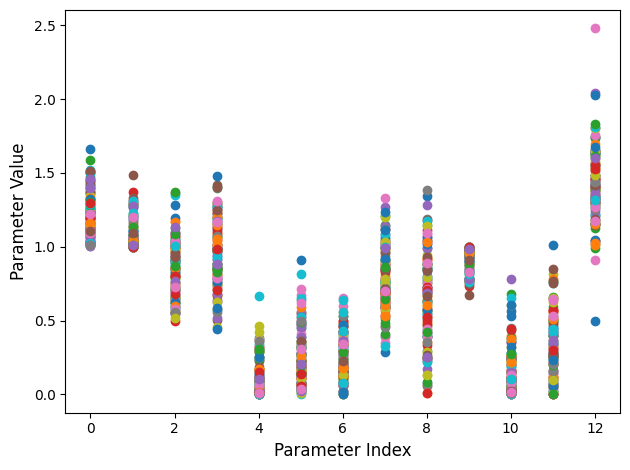

In [8]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

In [9]:
theta_opt[0]

array([1.5085497 , 1.189102  , 1.2838918 , 0.88042754, 0.3805814 ,
       0.38809043, 0.15685856, 0.6876284 , 0.2286601 , 0.8409705 ,
       0.1567103 , 0.01159689, 1.4589677 ], dtype=float32)

In [10]:
_th = theta_opt[0].copy()
display(mitral_output(_th, x, m, n_r, n_b, n_y))
_th[12] = 1.8
display(mitral_output(_th, x, m, n_r, n_b, n_y))


(Array([0.14378692, 0.14378692], dtype=float32),
 Array([0.23029009, 0.23029009], dtype=float32),
 Array([0.34891027, 0.34891027], dtype=float32),
 Array([0.2, 0.2], dtype=float32))

(Array([0.14821409, 0.14821409], dtype=float32),
 Array([0.18473798, 0.18473798], dtype=float32),
 Array([0.34891027, 0.34891027], dtype=float32),
 Array([0.20216815, 0.20216815], dtype=float32))

Processing 117 samples...
  Sample 1/117...
  Sample 101/117...
Completed processing 117 samples


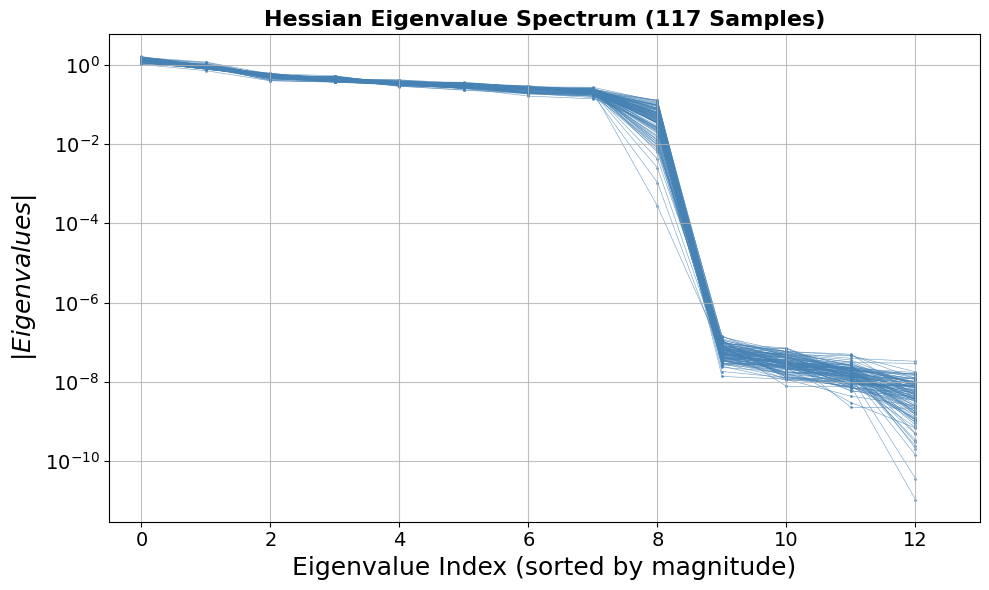

In [11]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
all_eigenvectors.shape

(117, 13, 13)

n_g index = 12, ε = 0.1, PROFILE_RIDGE = 1e-07
sample | quad δᵀHδ | linear gᵀδ | ‖g‖
     0 | -1.106986e-04 | 1.898179e-03 | 1.128797e+00
     1 | -5.263903e-04 | 8.274473e-03 | 1.170851e+00
     2 | -4.087915e-04 | 6.861384e-03 | 1.075246e+00
     3 | -1.730620e-04 | 3.422356e-03 | 1.101389e+00
     4 | -2.345678e-04 | 4.376306e-03 | 1.101506e+00
     5 | -4.316063e-04 | 7.242162e-03 | 1.123709e+00
     6 | -4.411701e-04 | 7.457014e-03 | 1.117252e+00
     7 | -1.399626e-03 | 1.834900e-02 | 1.142570e+00
     8 | -8.519429e-04 | 1.560348e-02 | 1.134397e+00
     9 | -1.208163e-03 | 1.939302e-02 | 1.123794e+00
    10 | -5.188926e-04 | 1.026340e-02 | 1.193423e+00
    11 | -3.929965e-04 | 7.092559e-03 | 1.155621e+00
    12 | -3.971909e-04 | 7.517557e-03 | 1.138923e+00
    13 | -1.072716e-03 | 1.619116e-02 | 1.089176e+00
    14 | -1.110228e-03 | 1.397303e-02 | 1.107366e+00
    15 | -1.055106e-03 | 1.313766e-02 | 1.135599e+00
    16 | -5.112971e-04 | 8.312466e-03 | 1.134113e+00
    17 | -6.05

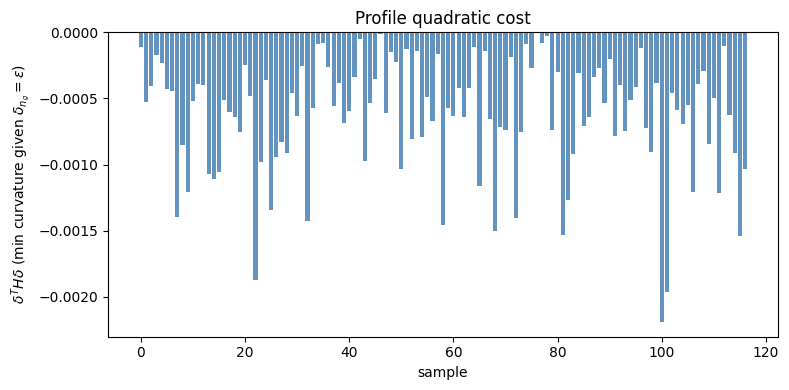

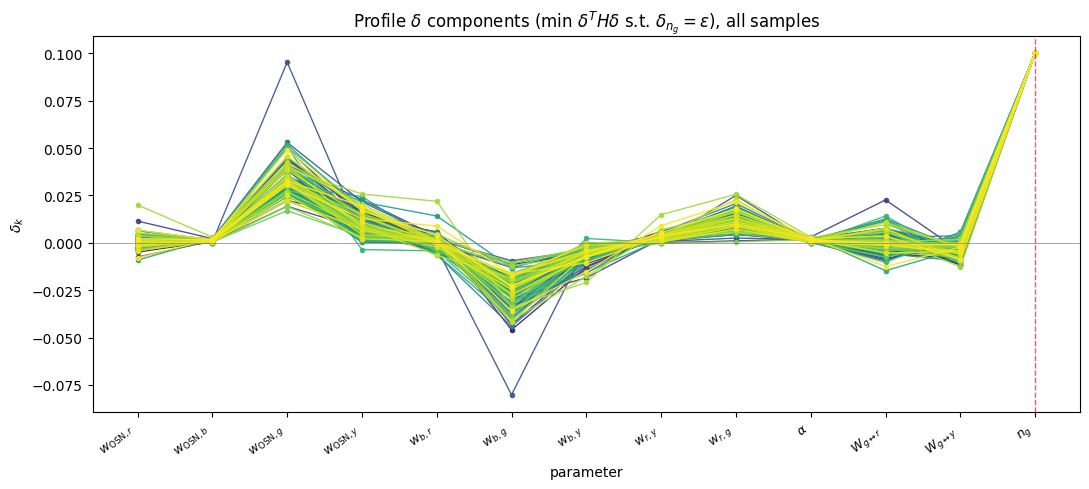

In [ ]:
# Conditioned profile direction: min δᵀHδ subject to δ[12] = ε (n_g index)
NG_IDX = 12
EPSILON = 0.1  # raw n_g increment; quadratic cost scales as ε²

free_idx = np.arange(NG_IDX)  # 0..11
I_ff = np.eye(free_idx.size)
# Ridge on H_ff: (H_ff + λ I) δ_f = b. Raw H_ff⁻¹ blows up when cond(H_ff) is huge (e.g. 1e10+).
PROFILE_RIDGE = 1e-7  # increase if δ still explodes; decrease to approach exact constrained minimizer

profile_deltas = np.zeros((n_samples, n_params))
quad_costs = np.zeros(n_samples)
linear_costs = np.zeros(n_samples)
grad_norms = np.zeros(n_samples)

for i in range(n_samples):
    theta_star = jnp.array(theta_samples[i, :])
    H = np.asarray(jnp.squeeze(hessian(theta_star)))
    g = np.asarray(grad(theta_star))
    H_ff = H[np.ix_(free_idx, free_idx)]
    H_f_ng = H[free_idx, NG_IDX]
    b = -H_f_ng * EPSILON
    H_solve = H_ff + PROFILE_RIDGE * I_ff
    try:
        delta_f = np.linalg.solve(H_solve, b)
    except np.linalg.LinAlgError:
        delta_f, _, _, _ = np.linalg.lstsq(H_solve, b, rcond=None)
    delta = np.zeros(n_params)
    delta[free_idx] = delta_f
    delta[NG_IDX] = EPSILON
    quad_costs[i] = float(delta @ H @ delta)
    linear_costs[i] = float(g @ delta)
    grad_norms[i] = float(np.linalg.norm(g))
    profile_deltas[i] = delta

print(f"n_g index = {NG_IDX}, ε = {EPSILON}, PROFILE_RIDGE = {PROFILE_RIDGE}")
print("sample | quad δᵀHδ | linear gᵀδ | ‖g‖")
for i in range(n_samples):
    print(f"  {i:4d} | {quad_costs[i]:12.6e} | {linear_costs[i]:12.6e} | {grad_norms[i]:12.6e}")

# Overlap with smallest-|λ| Hessian eigenvectors (columns are sorted |λ| descending → tail is near-null)
N_NEAR = min(3, n_params)
overlap_abs = np.zeros((n_samples, N_NEAR))
for i in range(n_samples):
    d = profile_deltas[i]
    dn = d / (np.linalg.norm(d) + 1e-30)
    for j in range(N_NEAR):
        v = all_eigenvectors[i, :, -(j + 1)]
        vn = v / (np.linalg.norm(v) + 1e-30)
        overlap_abs[i, j] = abs(float(np.dot(vn, dn)))

print("\n|cos| between unit profile δ and eigenvectors with smallest |λ| (j=0 smallest, j=1 next, …)")
for i in range(n_samples):
    print(f"  sample {i}: {overlap_abs[i]}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(n_samples), quad_costs, color="steelblue", alpha=0.85)
ax.set_xlabel("sample")
ax.set_ylabel(r"$\delta^T H \delta$ (min curvature given $\delta_{n_g}=\varepsilon$)")
ax.set_title("Profile quadratic cost")
# ax.set_yscale("symlog", linthresh=1e-12)  # δᵀHδ can be ≤0 (indefinite H); log y breaks
plt.tight_layout()
plt.show()

# All δ components on one plot (one curve per sample)
# Names align with unpack_theta(theta, m): one scalar per index
PARAM_NAMES = [
    r"$w_{\mathrm{OSN},r}$",
    r"$w_{\mathrm{OSN},b}$",
    r"$w_{\mathrm{OSN},g}$",
    r"$w_{\mathrm{OSN},y}$",
    r"$w_{b,r}$",
    r"$w_{b,g}$",
    r"$w_{b,y}$",
    r"$w_{r,y}$",
    r"$w_{r,g}$",
    r"$\alpha$",
    r"$W_{g\leftrightarrow r}$",
    r"$W_{g\leftrightarrow y}$",
    r"$n_g$",
]
assert len(PARAM_NAMES) == n_params
fig, ax = plt.subplots(figsize=(11, 5))
param_idx = np.arange(n_params)
colors = plt.cm.viridis(np.linspace(0, 1, max(n_samples, 2)))
for i in range(n_samples):
    ax.plot(
        param_idx,
        profile_deltas[i, :],
        "o-",
        ms=3,
        lw=1,
        alpha=0.9,
        color=colors[i],
        label=f"sample {i}" if n_samples <= 15 else None,
    )
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(NG_IDX, color="crimson", ls="--", lw=1, alpha=0.7, label=r"$n_g$")
ax.set_xlabel("parameter")
ax.set_ylabel(r"$\delta_k$")
ax.set_title(
    r"Profile $\delta$ components (min $\delta^T H \delta$ s.t. $\delta_{n_g}=\varepsilon$), all samples"
)
ax.set_xticks(param_idx)
ax.set_xticklabels(PARAM_NAMES, rotation=40, ha="right", fontsize=9)
# ax.set_yscale("symlog", linthresh=1e-10)  # linear y hides structure when a few |δ_k| dominate
if n_samples <= 15:
    ax.legend(ncol=4, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

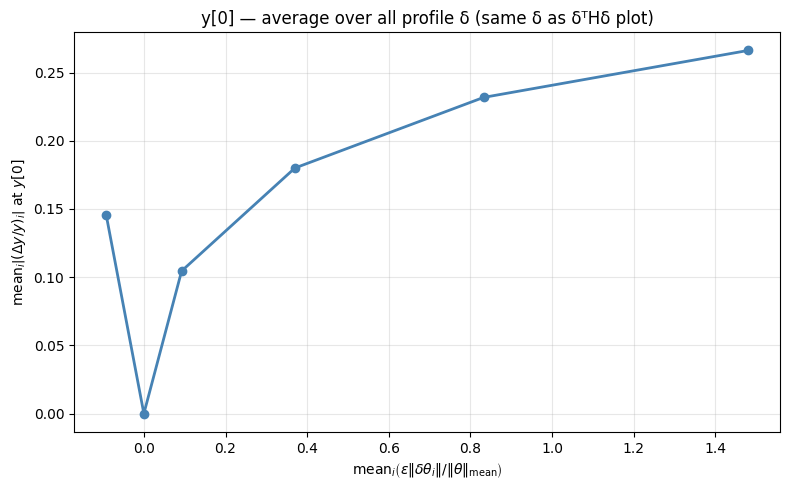

In [18]:
# |Δy/y| vs ε·||δθ||/||θ|| along the same constrained profile as above (δ from min δᵀHδ s.t. δ_{n_g}=ε).
# Scaling: profile_deltas was computed at δ_{n_g}=EPSILON; δ(ε) = (ε/EPSILON)·profile_deltas, so δ with δ_{n_g}=1 is profile_deltas/EPSILON.

e_vals = np.arange(-2, 2 + 0.2, 0.5)


def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)


mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

theta_batch = jnp.array(theta_samples)
delta_unit = np.asarray(profile_deltas) / EPSILON
delta_unit_norms = np.linalg.norm(delta_unit, axis=1)

mean_norm_theta = np.mean(np.linalg.norm(theta_batch, axis=1))

_, _, _, y_baseline = mitral_output_batch(theta_batch)
y_baseline = np.array(y_baseline)

# One point per ε: average over all profile δ(theta_i) from the δᵀHδ plot (one δ per sample).
x_mean_per_e = []
y_mean_abs_rel_per_e = []

for e in e_vals:
    theta_step = theta_batch + float(e) * jnp.asarray(delta_unit)
    _, _, _, y = mitral_output_batch(theta_step)
    y = np.array(y)
    theta_ratio = e * np.abs(e) * delta_unit_norms / mean_norm_theta
    j = 0
    y0 = y_baseline[:, j]
    rel = np.where(
        np.abs(y0) > 1e-12,
        (y[:, j] - y0) / y0,
        y[:, j] - y0,
    )
    x_mean_per_e.append(np.mean(theta_ratio))
    y_mean_abs_rel_per_e.append(np.mean(np.abs(rel)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_mean_per_e, y_mean_abs_rel_per_e, "o-", color="steelblue", lw=2, ms=6)
ax.set_xlabel(
    r"$\mathrm{mean}_i\left(\epsilon \|\delta\theta_i\| / \|\theta\|_{\mathrm{mean}}\right)$"
)
ax.set_ylabel(r"$\mathrm{mean}_i \left|(\Delta y / y)_i\right|$ at $y[0]$")
ax.set_title("y[0] — average over all profile δ (same δ as δᵀHδ plot)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
